# Análisis comparativo: Egresados 2022 vs Ingresos a Posgrados 2023
Este cuaderno analiza la relación entre los egresados de programas de licenciatura en 2022 y los ingresos a programas de posgrado en inteligencia artificial y análisis de datos en 2023.

In [ ]:
# Cargar librerías necesarias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
#  Subir archivos
from google.colab import files
uploaded = files.upload()

Saving Ingresos_Posgrados_IA_Datos_2023.xlsx to Ingresos_Posgrados_IA_Datos_2023.xlsx
Saving Egresados_Licenciaturas_2022.xlsx to Egresados_Licenciaturas_2022.xlsx


In [ ]:
# Leer los datos
egresados = pd.read_excel('Egresados_Licenciaturas_2022.xlsx')
ingresos = pd.read_excel('Ingresos_Posgrados_IA_Datos_2023.xlsx')

# Vista previa
egresados.head()

,Universidad,Ciudad,Departamento,Programa_Licenciatura,Total_Egresados_2022
0,COLEGIO MAYOR DE NUESTRA SEÑORA DEL ROSARIO,"Bogotá, D.C.",Bogotá D.C.,LICENCIATURA EN CIENCIAS SOCIALES,2
1,CONSERVATORIO DEL TOLIMA,Ibagué,Tolima,LICENCIATURA EN MUSICA,36
2,CORPORACION ESCUELA TECNOLOGICA DEL ORIENTE,Bucaramanga,Santander,LICENCIATURA EN PEDAGOGIA INFANTIL,44
3,CORPORACION INTERNACIONAL PARA EL DESARROLLO E...,"Bogotá, D.C.",Bogotá D.C.,LICENCIATURA EN PREESCOLAR,1
4,CORPORACION UNIVERSIDAD DE LA COSTA CUC,Barranquilla,Atlántico,LICENCIATURA EN EDUCACIÓN BÁSICA PRIMARIA,39


In [ ]:
# Vista previa
ingresos.head()

,Universidad,Ciudad,Departamento,Programa_Posgrado,Nivel_Formacion,Ingresos_2023
0,CORPORACION UNIVERSITARIA IBEROAMERICANA,"Bogotá, D.C.","Bogotá, D.C.",ESPECIALIZACION EN ANALITICA Y BIG DATA,Especialización universitaria,50
1,CORPORACION UNIVERSITARIA MINUTO DE DIOS -UNIM...,"Bogotá, D.C.","Bogotá, D.C.",ESPECIALIZACIÓN EN BIG DATA,Especialización universitaria,9
2,CORPORACION UNIVERSITARIA MINUTO DE DIOS -UNIM...,"Bogotá, D.C.","Bogotá, D.C.",ESPECIALIZACIÓN EN INTELIGENCIA ARTIFICIAL,Especialización universitaria,160
3,"ESEIT - ESCUELA SUPERIOR DE EMPRESA, INGENIERÍ...","Bogotá, D.C.","Bogotá, D.C.",ESPECIALIZACIÓN EN BIG DATA Y ANALÍTICA DE DATOS,Especialización universitaria,118
4,FUNDACION UNIVERSITARIA INTERNACIONAL DE LA RI...,"Bogotá, D.C.","Bogotá, D.C.",ESPECIALIZACIÓN EN INTELIGENCIA ARTIFICIAL,Especialización universitaria,38


In [ ]:
# Unificar nombres de columnas o instituciones si es necesario
# Normalizar nombres para posibles cruces posteriores
egresados['Universidad'] = egresados['Universidad'].str.upper().str.strip()
ingresos['Universidad'] = ingresos['Universidad'].str.upper().str.strip()

In [ ]:
#  Análisis descriptivo
egresados_total = egresados.groupby('Ciudad')['Total_Egresados_2022'].sum().sort_values(ascending=False)
ingresos_total = ingresos.groupby('Ciudad')['Ingresos_2023'].sum().sort_values(ascending=False)

display(egresados_total.head())
display(ingresos_total.head())

,Total_Egresados_2022
Ciudad,
"Bogotá, D.C.",8249
Medellín,1553
Pamplona,1160
Tunja,1070
Riohacha,1024


,Ingresos_2023
Ciudad,
"Bogotá, D.C.",702
Santiago de Cali,338
Medellín,278
Envigado,35


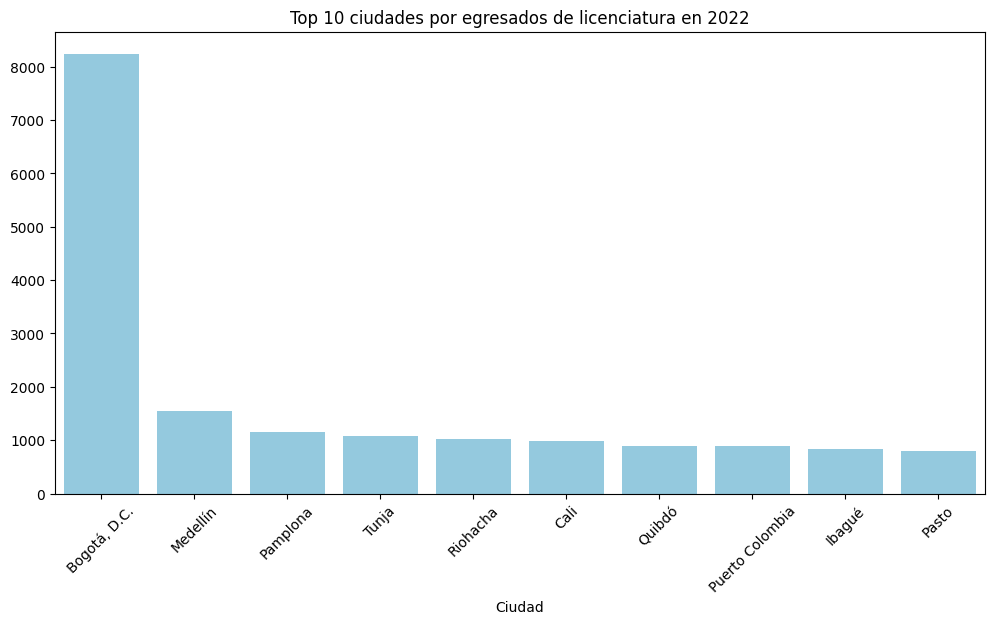

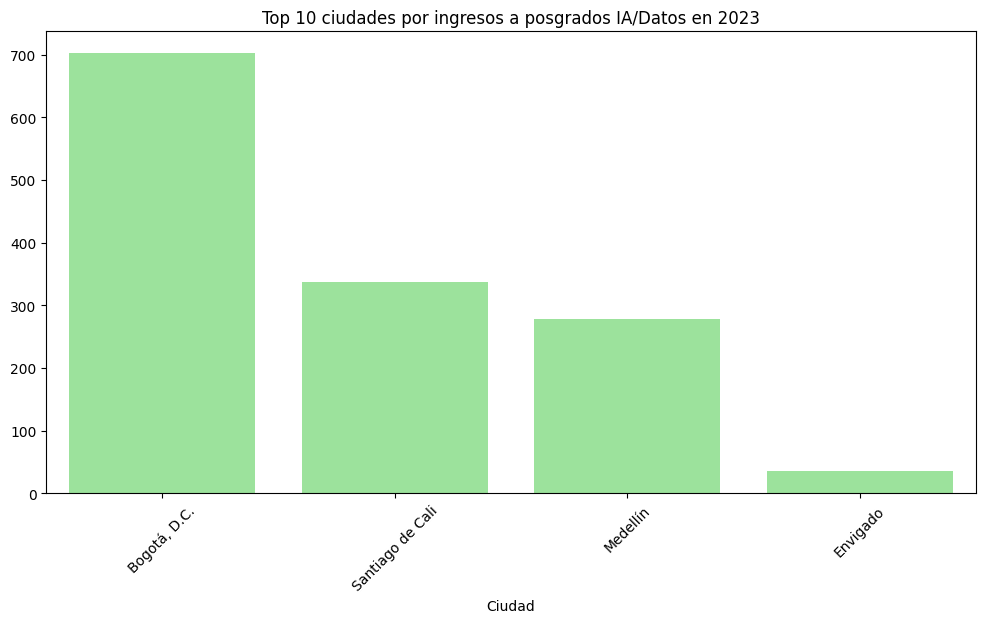

In [ ]:
# Comparación visual: ciudades con más egresados vs más ingresos
plt.figure(figsize=(12,6))
sns.barplot(x=egresados_total.index[:10], y=egresados_total.values[:10], color='skyblue')
plt.title('Top 10 ciudades por egresados de licenciatura en 2022')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12,6))
sns.barplot(x=ingresos_total.index[:10], y=ingresos_total.values[:10], color='lightgreen')
plt.title('Top 10 ciudades por ingresos a posgrados IA/Datos en 2023')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Análisis de correlación básica por ciudad

# Agrupar y sumar los valores por ciudad
egresados_ciudad = egresados.groupby('Ciudad')['Total_Egresados_2022'].sum().reset_index()
ingresos_ciudad = ingresos.groupby('Ciudad')['Ingresos_2023'].sum().reset_index()

# Unir ambas tablas por ciudad
merged = pd.merge(egresados_ciudad, ingresos_ciudad, on='Ciudad', how='inner')

# Calcular correlación solo entre las columnas numéricas
corr = merged[['Total_Egresados_2022', 'Ingresos_2023']].corr().iloc[0, 1]

# Imprimir resultado
print(f'Correlación entre egresados 2022 e ingresos 2023: {corr:.2f}')


Correlación entre egresados 2022 e ingresos 2023: 1.00


,Programa_Licenciatura,Total_Egresados_2022
236,LICENCIATURA EN PEDAGOGÍA INFANTIL,2675
147,LICENCIATURA EN EDUCACIÓN INFANTIL,1552
40,LICENCIATURA EN CIENCIAS SOCIALES,1076
234,LICENCIATURA EN PEDAGOGIA INFANTIL,835
64,LICENCIATURA EN EDUCACION BASICA CON ENFASIS E...,832
...,...,...
140,"LICENCIATURA EN EDUCACIÓN FISICA,RECREACION Y ...",1
146,"LICENCIATURA EN EDUCACIÓN FÍSICA, RECREACIÓN Y...",1
142,LICENCIATURA EN EDUCACIÓN FÍSICA RECREACIÓN Y ...,1
153,LICENCIATURA EN EDUCACIóN BáSICA CON ENFASIS E...,1


<ipython-input-11-a13055d9c420>:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=egresados_por_licenciatura.head(10),


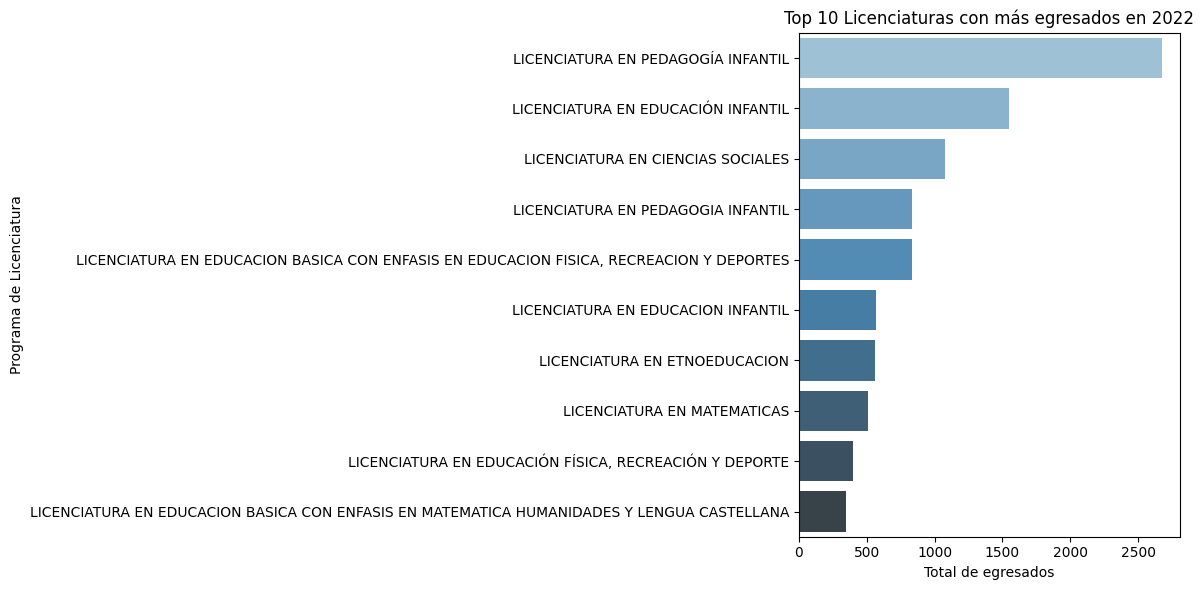

In [ ]:
# 📚 Agrupar egresados por programa de licenciatura
egresados_por_licenciatura = egresados.groupby('Programa_Licenciatura')['Total_Egresados_2022'].sum().reset_index()

# Ordenar de mayor a menor
egresados_por_licenciatura = egresados_por_licenciatura.sort_values(by='Total_Egresados_2022', ascending=False)

# Mostrar tabla
display(egresados_por_licenciatura)

# 🔢 Gráfico de barras de las 10 licenciaturas con más egresados
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.barplot(data=egresados_por_licenciatura.head(10),
            x='Total_Egresados_2022',
            y='Programa_Licenciatura',
            palette='Blues_d')

plt.title('Top 10 Licenciaturas con más egresados en 2022')
plt.xlabel('Total de egresados')
plt.ylabel('Programa de Licenciatura')
plt.tight_layout()
plt.show()

,Programa_Licenciatura,Total_Egresados_2022
2,LICENCIATURA EN MATEMATICAS,511
0,LICENCIATURA EN EDUCACION BASICA CON ENFASIS E...,351
7,LICENCIATURA EN MATEMÁTICAS,196
6,LICENCIATURA EN MATEMATICAS Y FISICA,127
1,LICENCIATURA EN EDUCACION BASICA CON ENFASIS E...,90
5,LICENCIATURA EN MATEMATICAS Y ESTADISTICA,32
9,LICENCIATURA EN MATEMÁTICAS Y FÍSICA,16
10,LICENCIATURA EN TECNOLOGIA E INFORMATICA,9
3,LICENCIATURA EN MATEMATICAS E INFORMATICA,4
8,LICENCIATURA EN MATEMÁTICAS E INFORMÁTICA,4


<ipython-input-13-7afbd08c5905>:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=conteo_matematicas,


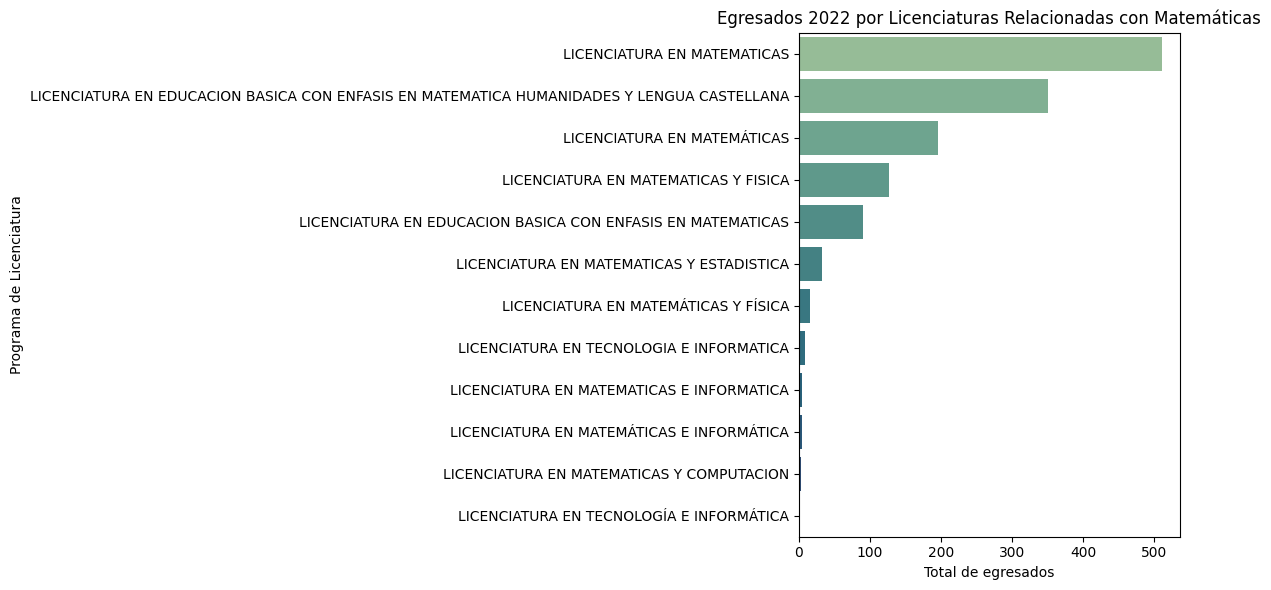

In [ ]:
# ✅ Lista de licenciaturas relacionadas con matemáticas
lics_matematicas = [
    'LICENCIATURA EN MATEMATICAS',
    'LICENCIATURA EN MATEMATICAS Y FISICA',
    'LICENCIATURA EN MATEMATICAS Y ESTADISTICA',
    'LICENCIATURA EN MATEMATICAS Y COMPUTACION',
    'LICENCIATURA EN MATEMATICAS E INFORMATICA',
    'LICENCIATURA EN MATEMÁTICAS',
    'LICENCIATURA EN MATEMÁTICAS E INFORMÁTICA',
    'LICENCIATURA EN MATEMÁTICAS Y FÍSICA',
    'LICENCIATURA EN EDUCACION BASICA CON ENFASIS EN MATEMATICAS',
    'LICENCIATURA EN EDUCACION BASICA CON ENFASIS EN MATEMATICA HUMANIDADES Y LENGUA CASTELLANA',
    'LICENCIATURA EN TECNOLOGIA E INFORMATICA',
    'LICENCIATURA EN TECNOLOGÍA E INFORMÁTICA'
]

# 📊 Filtrar egresados por esas licenciaturas
egresados_matematicas = egresados[egresados['Programa_Licenciatura'].isin(lics_matematicas)]

# 📈 Agrupar por programa y contar total de egresados
conteo_matematicas = egresados_matematicas.groupby('Programa_Licenciatura')['Total_Egresados_2022'].sum().reset_index()

# 📌 Ordenar resultados
conteo_matematicas = conteo_matematicas.sort_values(by='Total_Egresados_2022', ascending=False)

# 👀 Mostrar tabla
display(conteo_matematicas)

# 📉 Gráfico de barras
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.barplot(data=conteo_matematicas,
            x='Total_Egresados_2022',
            y='Programa_Licenciatura',
            palette='crest')

plt.title('Egresados 2022 por Licenciaturas Relacionadas con Matemáticas')
plt.xlabel('Total de egresados')
plt.ylabel('Programa de Licenciatura')
plt.tight_layout()
plt.show()


,Ciudad,Universidad,Tipo_Programa,Ingresos_2023
20,Santiago de Cali,PONTIFICIA UNIVERSIDAD JAVERIANA,Análisis de Datos,167
6,"Bogotá, D.C.",FUNDACIÓN UNIVERSITARIA COMPENSAR,Análisis de Datos,165
2,"Bogotá, D.C.",CORPORACION UNIVERSITARIA MINUTO DE DIOS -UNIM...,IA,160
21,Santiago de Cali,UNIVERSIDAD AUTONOMA DE OCCIDENTE,IA,119
3,"Bogotá, D.C.","ESEIT - ESCUELA SUPERIOR DE EMPRESA, INGENIERÍ...",Análisis de Datos,118
18,Medellín,UNIVERSIDAD EAFIT-,Análisis de Datos,73
17,Medellín,UNIVERSIDAD DE ANTIOQUIA,Análisis de Datos,65
7,"Bogotá, D.C.",PONTIFICIA UNIVERSIDAD JAVERIANA,IA,59
14,Medellín,INSTITUCION UNIVERSITARIA DIGITAL DE ANTIOQUIA...,Análisis de Datos,56
22,Santiago de Cali,UNIVERSIDAD ICESI,Análisis de Datos,52


<ipython-input-17-ee27114e7871>:29: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




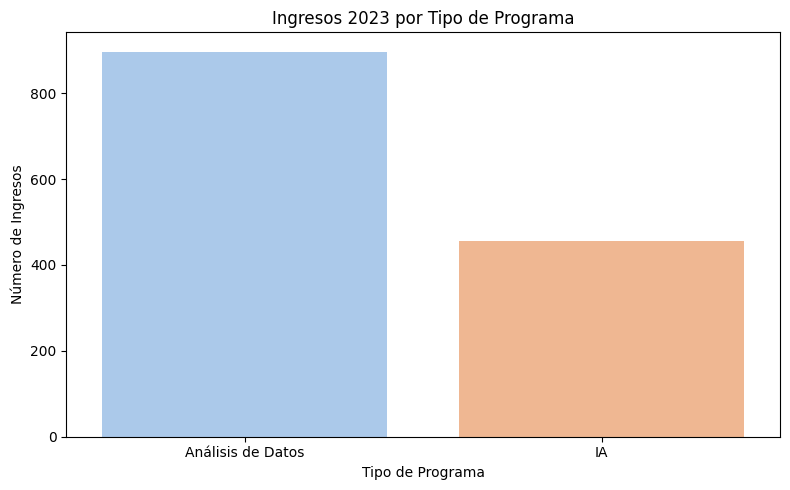

<ipython-input-17-ee27114e7871>:41: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




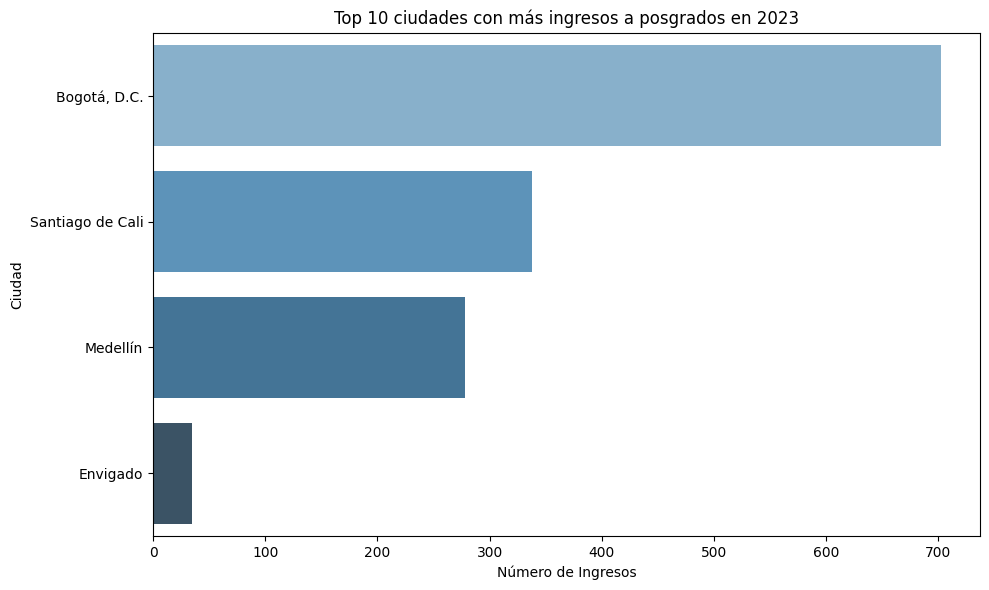

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar archivo
ingresos = pd.read_excel('Ingresos_Posgrados_IA_Datos_2023.xlsx')

# Clasificar tipo de programa
def clasificar_programa(nombre):
    nombre = nombre.upper()
    if 'INTELIGENCIA ARTIFICIAL' in nombre:
        return 'IA'
    elif 'DATOS' in nombre or 'ANALÍTICA' in nombre or 'BIG DATA' in nombre:
        return 'Análisis de Datos'
    else:
        return 'Otro'

ingresos['Tipo_Programa'] = ingresos['Programa_Posgrado'].apply(clasificar_programa)

# Agrupar por ciudad, universidad y tipo de programa
resumen = ingresos.groupby(['Ciudad', 'Universidad', 'Tipo_Programa'], as_index=False)['Ingresos_2023'].sum()
resumen = resumen.sort_values(by='Ingresos_2023', ascending=False)

# Mostrar la tabla
display(resumen)

# Gráfico de barras por tipo de programa
plt.figure(figsize=(8, 5))
sns.barplot(data=ingresos.groupby('Tipo_Programa')['Ingresos_2023'].sum().reset_index(),
            x='Tipo_Programa', y='Ingresos_2023', palette='pastel')
plt.title('Ingresos 2023 por Tipo de Programa')
plt.xlabel('Tipo de Programa')
plt.ylabel('Número de Ingresos')
plt.tight_layout()
plt.show()

# Gráfico de barras por ciudad (top 10)
top_ciudades = ingresos.groupby('Ciudad')['Ingresos_2023'].sum().reset_index().sort_values(by='Ingresos_2023', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_ciudades, x='Ingresos_2023', y='Ciudad', palette='Blues_d')
plt.title('Top 10 ciudades con más ingresos a posgrados en 2023')
plt.xlabel('Número de Ingresos')
plt.ylabel('Ciudad')
plt.tight_layout()
plt.show()


In [ ]:
# Clasificar tipo de programa
def clasificar_programa(nombre):
    nombre = nombre.upper()
    if 'INTELIGENCIA ARTIFICIAL' in nombre:
        return 'IA'
    elif 'DATOS' in nombre or 'ANALÍTICA' in nombre or 'BIG DATA' in nombre:
        return 'Análisis de Datos'
    else:
        return 'Otro'

ingresos['Tipo_Programa'] = ingresos['Programa_Posgrado'].apply(clasificar_programa)

# Pregunta 1: Universidades con 100% de ingresos en un solo tipo de programa
grupo = ingresos.groupby(['Universidad', 'Tipo_Programa'])['Ingresos_2023'].sum().reset_index()
total_uni = grupo.groupby('Universidad')['Ingresos_2023'].sum().reset_index().rename(columns={'Ingresos_2023': 'Total_Univ'})
concentracion = grupo.merge(total_uni, on='Universidad')
concentracion['Proporcion'] = concentracion['Ingresos_2023'] / concentracion['Total_Univ'] * 100
exclusivas = concentracion[concentracion['Proporcion'] == 100]

# Mostrar universidades con concentración exclusiva en un tipo de programa
print("Universidades con 100% de concentración en un solo tipo de programa:")
print(exclusivas[['Universidad', 'Tipo_Programa', 'Ingresos_2023']])

# Pregunta 2: ¿Qué universidad concentra el mayor porcentaje de ingresos en IA en todo el país?
ia_universidades = grupo[grupo['Tipo_Programa'] == 'IA'].copy()
total_ia = ia_universidades['Ingresos_2023'].sum()
ia_universidades['Porcentaje_Nacional_IA'] = ia_universidades['Ingresos_2023'] / total_ia * 100
ia_universidades_ordenadas = ia_universidades.sort_values(by='Porcentaje_Nacional_IA', ascending=False)

print("\nUniversidades con mayor participación en ingresos IA a nivel nacional:")
print(ia_universidades_ordenadas[['Universidad', 'Ingresos_2023', 'Porcentaje_Nacional_IA']])

Universidades con 100% de concentración en un solo tipo de programa:
                                          Universidad      Tipo_Programa  \
0            CORPORACION UNIVERSITARIA IBEROAMERICANA  Análisis de Datos   
3   ESEIT - ESCUELA SUPERIOR DE EMPRESA, INGENIERÍ...  Análisis de Datos   
4   FUNDACION UNIVERSITARIA INTERNACIONAL DE LA RI...                 IA   
5               FUNDACION UNIVERSITARIA KONRAD LORENZ  Análisis de Datos   
6                   FUNDACIÓN UNIVERSITARIA COMPENSAR  Análisis de Datos   
7   INSTITUCION UNIVERSITARIA DIGITAL DE ANTIOQUIA...  Análisis de Datos   
8             INSTITUCIÓN UNIVERSITARIA PASCUAL BRAVO  Análisis de Datos   
11                  UNIVERSIDAD AUTONOMA DE OCCIDENTE                 IA   
12                    UNIVERSIDAD CATÓLICA LUIS AMIGÓ  Análisis de Datos   
13                           UNIVERSIDAD DE ANTIOQUIA  Análisis de Datos   
14                           UNIVERSIDAD DE LOS ANDES                 IA   
15                 

In [ ]:
import plotly.express as px

# IA: escala azul continua
df_ia = universidad_tipo[universidad_tipo['Tipo_Programa'] == 'IA']

fig_ia = px.treemap(
    df_ia,
    path=['Tipo_Programa', 'Universidad'],
    values='Ingresos_2023',
    color='Ingresos_2023',
    color_continuous_scale='Blues',
    title='Ingresos 2023 – Inteligencia Artificial (escala azul)'
)
fig_ia.update_layout(margin=dict(t=40, l=10, r=10, b=10))
fig_ia.show()

# Análisis de Datos: escala roja continua
df_datos = universidad_tipo[universidad_tipo['Tipo_Programa'] == 'Análisis de Datos']

fig_datos = px.treemap(
    df_datos,
    path=['Tipo_Programa', 'Universidad'],
    values='Ingresos_2023',
    color='Ingresos_2023',
    color_continuous_scale='Reds',
    title='Ingresos 2023 – Análisis de Datos (escala roja)'
)
fig_datos.update_layout(margin=dict(t=40, l=10, r=10, b=10))
fig_datos.show()




In [ ]:
# 1. Ciudades principales a mostrar
ciudades_clave = ['Bogotá, D.C.', 'Medellín', 'Santiago de Cali', 'Barranquilla', 'Bucaramanga']

# 2. Licenciaturas específicas relacionadas con matemáticas
lics_especificas = [
    'LICENCIATURA EN MATEMATICAS',
    'LICENCIATURA EN MATEMATICAS Y FISICA',
    'LICENCIATURA EN MATEMATICAS Y COMPUTACION'
]

# 3. Normalizar nombres de ciudades
egresados['Ciudad'] = egresados['Ciudad'].str.strip()
ingresos['Ciudad'] = ingresos['Ciudad'].str.strip()

# 4. Filtrar egresados por ciudad y programa
egresados_filtrados = egresados[
    (egresados['Ciudad'].isin(ciudades_clave)) &
    (egresados['Programa_Licenciatura'].isin(lics_especificas))
]

# Agrupar egresados por ciudad y licenciatura
tabla_egresados = egresados_filtrados.groupby(
    ['Ciudad', 'Programa_Licenciatura']
)['Total_Egresados_2022'].sum().unstack().fillna(0)

# 5. Filtrar ingresos por ciudad y tipo de programa
ingresos_filtrados = ingresos[
    (ingresos['Ciudad'].isin(ciudades_clave)) &
    (ingresos['Tipo_Programa'].isin(['IA', 'Análisis de Datos']))
]

# Agrupar ingresos por ciudad y tipo
tabla_ingresos = ingresos_filtrados.groupby(
    ['Ciudad', 'Tipo_Programa']
)['Ingresos_2023'].sum().unstack().fillna(0)

# 6. Unir egresados + ingresos
tabla_cruzada = pd.concat([tabla_egresados, tabla_ingresos], axis=1).fillna(0).astype(int)

# 7. Reordenar columnas si están disponibles
columnas_orden = [
    'LICENCIATURA EN MATEMATICAS',
    'LICENCIATURA EN MATEMATICAS Y FISICA',
    'LICENCIATURA EN MATEMATICAS Y COMPUTACION',
    'IA',
    'Análisis de Datos'
]
columnas_existentes = [col for col in columnas_orden if col in tabla_cruzada.columns]
tabla_cruzada = tabla_cruzada[columnas_existentes]

# 8. Mostrar tabla
print(tabla_cruzada)

                  LICENCIATURA EN MATEMATICAS  \
Ciudad                                          
Bogotá, D.C.                               35   
Bucaramanga                                19   
Medellín                                    0   
Santiago de Cali                            0   

                  LICENCIATURA EN MATEMATICAS Y FISICA  \
Ciudad                                                   
Bogotá, D.C.                                         0   
Bucaramanga                                          0   
Medellín                                             8   
Santiago de Cali                                     0   

                  LICENCIATURA EN MATEMATICAS Y COMPUTACION   IA  \
Ciudad                                                             
Bogotá, D.C.                                              1  301   
Bucaramanga                                               0    0   
Medellín                                                  0   29   
Santiago de Cali

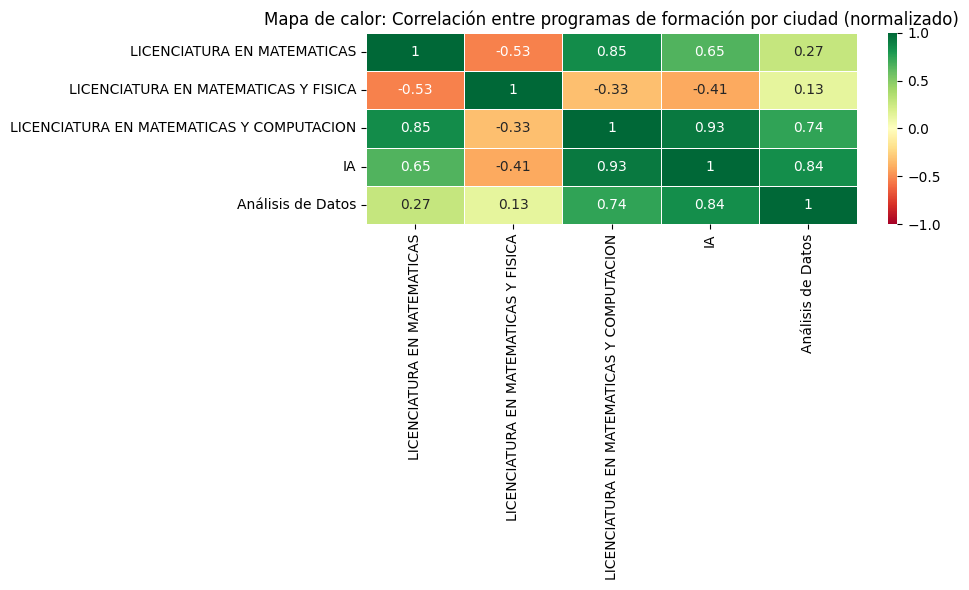

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Paso 1: Normalizar las columnas de la tabla (por columna)
scaler = MinMaxScaler()
tabla_norm = pd.DataFrame(scaler.fit_transform(tabla_cruzada),
                          columns=tabla_cruzada.columns,
                          index=tabla_cruzada.index)

# Paso 2: Calcular matriz de correlación
matriz_corr = tabla_norm.corr()

# Paso 3: Graficar heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(matriz_corr, annot=True, cmap='RdYlGn', vmin=-1, vmax=1, cbar=True, linewidths=0.5)
plt.title('Mapa de calor: Correlación entre programas de formación por ciudad (normalizado)')
plt.tight_layout()
plt.show()


Ecuación regresión múltiple - IA:
IA = 0.3953 + -0.7283 * LICENCIATURA EN MATEMATICAS + -0.2990 * LICENCIATURA EN MATEMATICAS Y FISICA + 1.3329 * LICENCIATURA EN MATEMATICAS Y COMPUTACION

Ecuación regresión múltiple - Análisis de Datos:
Análisis de Datos = 0.5461 + -1.0060 * LICENCIATURA EN MATEMATICAS + 0.0748 * LICENCIATURA EN MATEMATICAS Y FISICA + 1.4599 * LICENCIATURA EN MATEMATICAS Y COMPUTACION


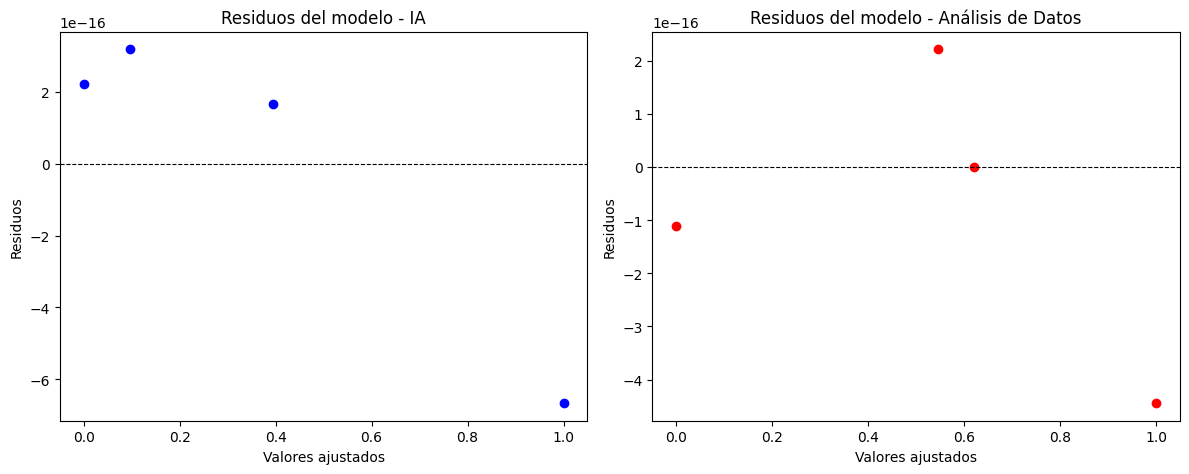

,Modelo,MAE,RMSE,R²
0,IA,3.434752e-16,3.945419e-16,1.0
1,Análisis de Datos,1.942890e-16,2.543841e-16,1.0


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Variables independientes
X = tabla_norm[['LICENCIATURA EN MATEMATICAS',
                'LICENCIATURA EN MATEMATICAS Y FISICA',
                'LICENCIATURA EN MATEMATICAS Y COMPUTACION']]

# Modelo 1: IA
y_ia = tabla_norm['IA']
modelo_ia = LinearRegression().fit(X, y_ia)
pred_ia = modelo_ia.predict(X)
residuos_ia = y_ia - pred_ia

# Modelo 2: Análisis de Datos
y_datos = tabla_norm['Análisis de Datos']
modelo_datos = LinearRegression().fit(X, y_datos)
pred_datos = modelo_datos.predict(X)
residuos_datos = y_datos - pred_datos

# Mostrar ecuaciones
ecuacion_ia = f"IA = {modelo_ia.intercept_:.4f} + " + " + ".join([
    f"{coef:.4f} * {var}" for coef, var in zip(modelo_ia.coef_, X.columns)])
ecuacion_datos = f"Análisis de Datos = {modelo_datos.intercept_:.4f} + " + " + ".join([
    f"{coef:.4f} * {var}" for coef, var in zip(modelo_datos.coef_, X.columns)])

print("Ecuación regresión múltiple - IA:")
print(ecuacion_ia)
print("\nEcuación regresión múltiple - Análisis de Datos:")
print(ecuacion_datos)

# Gráficos de residuos (solo puntos, sin línea lowess)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(pred_ia, residuos_ia, color='blue')
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Residuos del modelo - IA')
plt.xlabel('Valores ajustados')
plt.ylabel('Residuos')

plt.subplot(1, 2, 2)
plt.scatter(pred_datos, residuos_datos, color='red')
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Residuos del modelo - Análisis de Datos')
plt.xlabel('Valores ajustados')
plt.ylabel('Residuos')

plt.tight_layout()
plt.show()

# Tabla de errores
tabla_errores = pd.DataFrame({
    'Modelo': ['IA', 'Análisis de Datos'],
    'MAE': [mean_absolute_error(y_ia, pred_ia), mean_absolute_error(y_datos, pred_datos)],
    'RMSE': [mean_squared_error(y_ia, pred_ia)**0.5, mean_squared_error(y_datos, pred_datos)**0.5],
    'R²': [modelo_ia.score(X, y_ia), modelo_datos.score(X, y_datos)]
})

from IPython.display import display
display(tabla_errores)




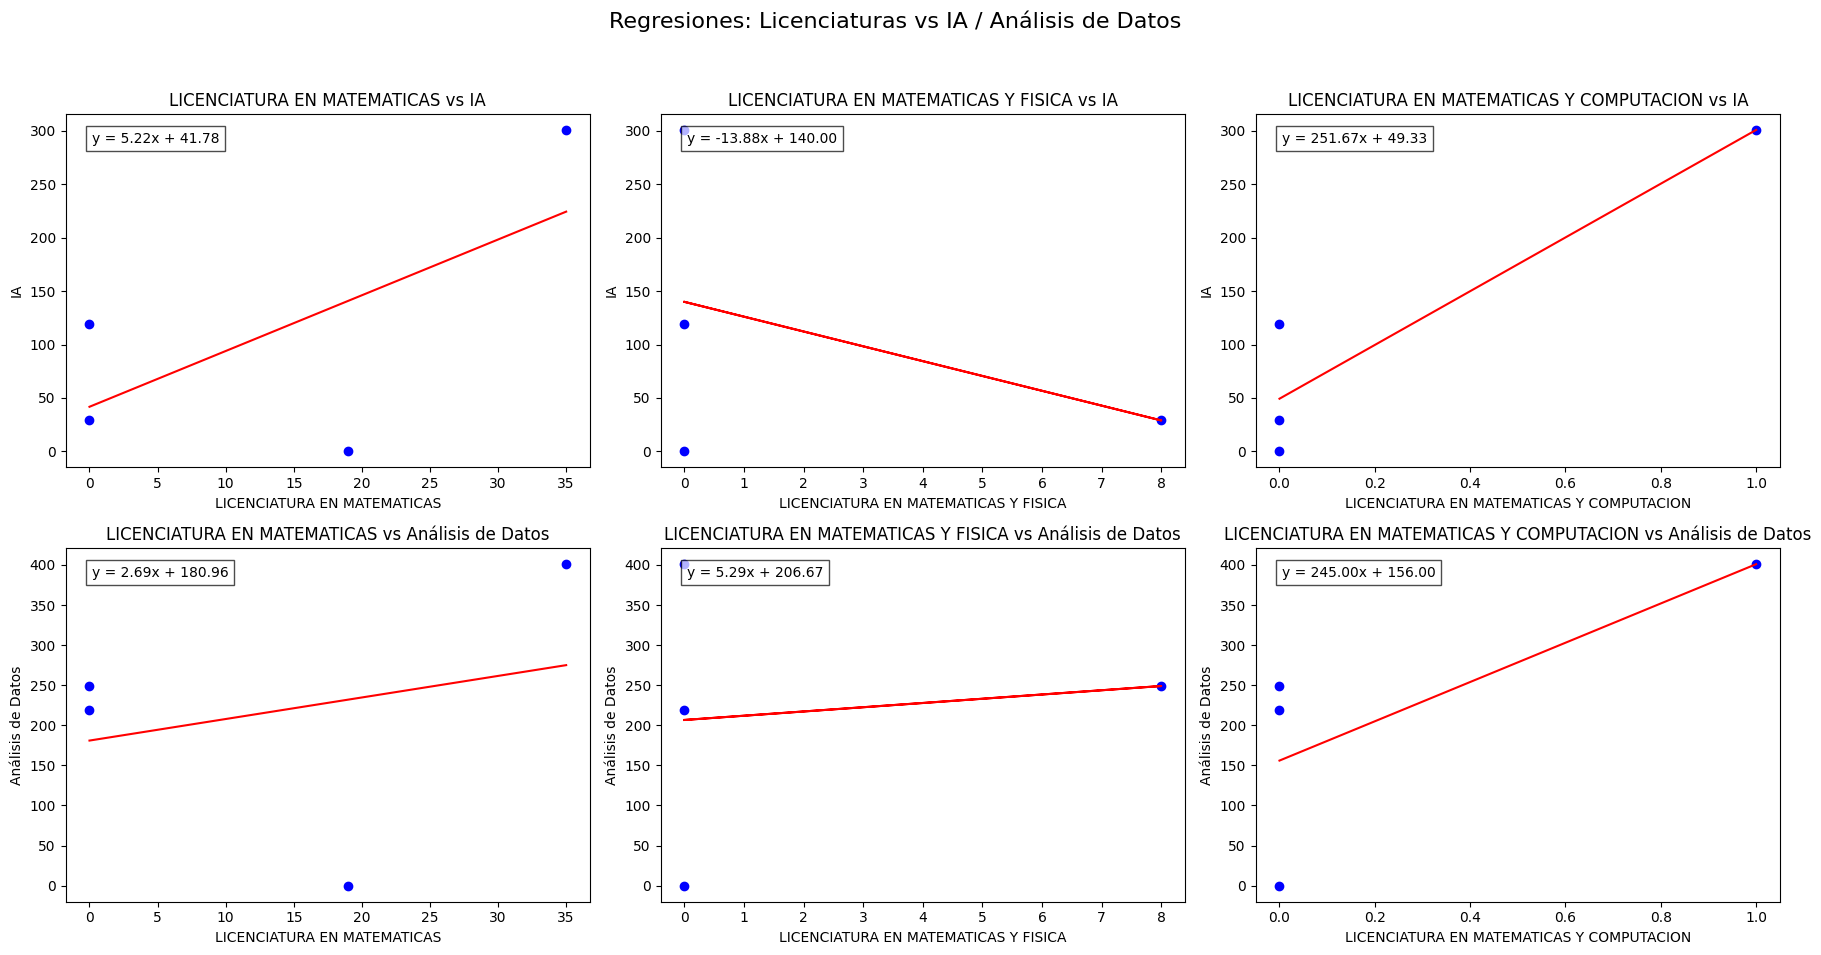

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import numpy as np

# Lista de pares (x, y)
regresiones = [
    ('LICENCIATURA EN MATEMATICAS', 'IA'),
    ('LICENCIATURA EN MATEMATICAS Y FISICA', 'IA'),
    ('LICENCIATURA EN MATEMATICAS Y COMPUTACION', 'IA'),
    ('LICENCIATURA EN MATEMATICAS', 'Análisis de Datos'),
    ('LICENCIATURA EN MATEMATICAS Y FISICA', 'Análisis de Datos'),
    ('LICENCIATURA EN MATEMATICAS Y COMPUTACION', 'Análisis de Datos')
]

# Crear la figura de subplots (2 filas, 3 columnas)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Regresiones: Licenciaturas vs IA / Análisis de Datos", fontsize=16)

# Graficar cada regresión
for idx, (x_col, y_col) in enumerate(regresiones):
    row = idx // 3
    col = idx % 3
    ax = axes[row, col]

    # Datos
    X = tabla_cruzada[[x_col]].values
    y = tabla_cruzada[y_col].values

    # Ajustar modelo
    modelo = LinearRegression()
    modelo.fit(X, y)
    y_pred = modelo.predict(X)

    # Gráfico
    ax.scatter(X, y, color='blue', label='Datos')
    ax.plot(X, y_pred, color='red', label='Regresión')
    ax.set_title(f'{x_col} vs {y_col}')
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)

    # Mostrar ecuación en el gráfico
    coef = modelo.coef_[0]
    inter = modelo.intercept_
    eq = f'y = {coef:.2f}x + {inter:.2f}'
    ax.text(0.05, 0.95, eq, transform=ax.transAxes,
            fontsize=10, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))

# Ajustar el diseño
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Lista para almacenar resultados
resultados = []

# Repetimos la lista de regresiones
regresiones = [
    ('LICENCIATURA EN MATEMATICAS', 'IA'),
    ('LICENCIATURA EN MATEMATICAS Y FISICA', 'IA'),
    ('LICENCIATURA EN MATEMATICAS Y COMPUTACION', 'IA'),
    ('LICENCIATURA EN MATEMATICAS', 'Análisis de Datos'),
    ('LICENCIATURA EN MATEMATICAS Y FISICA', 'Análisis de Datos'),
    ('LICENCIATURA EN MATEMATICAS Y COMPUTACION', 'Análisis de Datos')
]

# Calcular errores por regresión
for x_col, y_col in regresiones:
    X = tabla_cruzada[[x_col]].values
    y = tabla_cruzada[y_col].values

    modelo = LinearRegression()
    modelo.fit(X, y)
    y_pred = modelo.predict(X)

    # Cálculo de métricas
    mae = mean_absolute_error(y, y_pred)
    mse = mean_squared_error(y, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y, y_pred)

    resultados.append({
        'X (Licenciatura)': x_col,
        'Y (Programa)': y_col,
        'MAE': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE': round(rmse, 2),
        'R²': round(r2, 3)
    })

# Crear DataFrame y mostrarlo
df_errores = pd.DataFrame(resultados)
display(df_errores)


,X (Licenciatura),Y (Programa),MAE,MSE,RMSE,R²
0,LICENCIATURA EN MATEMATICAS,IA,76.87,7962.82,89.23,0.423
1,LICENCIATURA EN MATEMATICAS Y FISICA,IA,80.50,11490.50,107.19,0.167
2,LICENCIATURA EN MATEMATICAS Y COMPUTACION,IA,34.83,1925.17,43.88,0.861
3,LICENCIATURA EN MATEMATICAS,Análisis de Datos,116.02,18945.31,137.64,0.076
4,LICENCIATURA EN MATEMATICAS Y FISICA,Análisis de Datos,103.33,20157.17,141.98,0.016
5,LICENCIATURA EN MATEMATICAS Y COMPUTACION,Análisis de Datos,78.00,9238.50,96.12,0.549
